# Airbnb Data Analysis and Dashboard Creation

## Objective

The objective of this project is to analyze Airbnb listing data to understand pricing patterns, property distribution, room-type popularity, guest reviews, ratings, and availability.

The analysis will use Python, Pandas, Matplotlib, and Seaborn. The cleaned data and findings will then be used to develop an interactive Streamlit dashboard that enables users to explore Airbnb listings through filters and visualizations.


In [13]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Project paths
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

Project directory: d:\Adarsh\Hexa Solutions\Data Analytics Level 3\Projects\Assignment Projects\6 - AIRBNB Dashboarding\Airbnb_Data_Analysis
Data directory: d:\Adarsh\Hexa Solutions\Data Analytics Level 3\Projects\Assignment Projects\6 - AIRBNB Dashboarding\Airbnb_Data_Analysis\data


In [14]:
# Load the dataset
file_path = DATA_DIR / "listings.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (490, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20260616211424,2026-06-16,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://a0.muscache.com/pictures/44627226/0e72...,4621559,https://www.airbnb.com/users/show/4621559,1462661762635155041,https://www.airbnb.com/users/profile/146266176...,Kenneth,NaN,13,5,13,4,"New York, NY",I am a real down to earth & cool person.,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/4621559/profi...,NaN,1,NaN,NaN,t,t,NaN,THIRD WARD,NaN,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,1.0,1 bath,2.0,2.0,"[""Kitchen"", ""Essentials"", ""Heating"", ""Wifi"", ""...",$80.43,2027-03-31,2027-04-28,2252.0,80.43,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",28.0,1125.0,28.0,28.0,1125.0,1125.0,28.0,1125.0,NaN,t,0,0,0,77,2026-06-16,9,0,0,0,0,0,0.0,2014-07-01,2022-08-17,3.56,3.44,3.56,4.22,4.56,3.22,3.67,NaN,NaN,1,1,0,0,0.06
1,3820211,https://www.airbnb.com/rooms/3820211,20260616211424,2026-06-16,city scrape,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,19648678,https://www.airbnb.com/users/show/19648678,1463087024016718788,https://www.airbnb.com/users/profile/146308702...,Ming,NaN,11,10,11,10,"Albany, NY","Hello! I’m a proud resident of Albany, NY, whe...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/User/...,NaN,7,NaN,NaN,t,t,NaN,SIXTH WARD,NaN,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1.0,1 bath,1.0,1.0,"[""Free washer \u2013 In unit"", ""Microwave"", ""S...",$211.00,2026-07-20,2026-07-21,211.0,211.00,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",1.0,1125.0,1.0,3.0,1125.0,1125.0,2.7,1125.0,NaN,t,0,23,53,328,2026-06-16,317,8,0,162,9,48,10128.0,2014-08-15,2026-01-25,4.75,4.88,4.87,4.85,4.81,4.82,4.78,NaN,NaN,7,7,0,0,2.20
2,5651579,https://www.airbnb.com/rooms/5651579,20260616211424,2026-06-16,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",NaN,https://a0.muscache.com/pictures/b3fc42f3-6e5e...,29288920,https://www.airbnb.com/users/show/29288920,1465431505328745177,https://www.airbnb.com/users/profile/146543150...,Gregg,NaN,11,3,11,3,"Albany, NY",I am an Albany native .I have lived in Ireland...,NaN,NaN,NaN,f

In [ ]:
# Understand the dataset

# First five rows
display(df.head())

# Last five rows
display(df.tail())

# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print(df.columns.tolist())

# Data types and non-null counts
df.info()

# Numerical summary statistics
display(df.describe().T)

# Categorical summary statistics
display(df.describe(include="object").T)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20260616211424,2026-06-16,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://a0.muscache.com/pictures/44627226/0e72...,4621559,https://www.airbnb.com/users/show/4621559,1462661762635155041,https://www.airbnb.com/users/profile/146266176...,Kenneth,NaN,13,5,13,4,"New York, NY",I am a real down to earth & cool person.,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/4621559/profi...,NaN,1,NaN,NaN,t,t,NaN,THIRD WARD,NaN,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,1.0,1 bath,2.0,2.0,"[""Kitchen"", ""Essentials"", ""Heating"", ""Wifi"", ""...",$80.43,2027-03-31,2027-04-28,2252.0,80.43,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",28.0,1125.0,28.0,28.0,1125.0,1125.0,28.0,1125.0,NaN,t,0,0,0,77,2026-06-16,9,0,0,0,0,0,0.0,2014-07-01,2022-08-17,3.56,3.44,3.56,4.22,4.56,3.22,3.67,NaN,NaN,1,1,0,0,0.06
1,3820211,https://www.airbnb.com/rooms/3820211,20260616211424,2026-06-16,city scrape,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,19648678,https://www.airbnb.com/users/show/19648678,1463087024016718788,https://www.airbnb.com/users/profile/146308702...,Ming,NaN,11,10,11,10,"Albany, NY","Hello! I’m a proud resident of Albany, NY, whe...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/User/...,NaN,7,NaN,NaN,t,t,NaN,SIXTH WARD,NaN,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1.0,1 bath,1.0,1.0,"[""Free washer \u2013 In unit"", ""Microwave"", ""S...",$211.00,2026-07-20,2026-07-21,211.0,211.00,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",1.0,1125.0,1.0,3.0,1125.0,1125.0,2.7,1125.0,NaN,t,0,23,53,328,2026-06-16,317,8,0,162,9,48,10128.0,2014-08-15,2026-01-25,4.75,4.88,4.87,4.85,4.81,4.82,4.78,NaN,NaN,7,7,0,0,2.20
2,5651579,https://www.airbnb.com/rooms/5651579,20260616211424,2026-06-16,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",NaN,https://a0.muscache.com/pictures/b3fc42f3-6e5e...,29288920,https://www.airbnb.com/users/show/29288920,1465431505328745177,https://www.airbnb.com/users/profile/146543150...,Gregg,NaN,11,3,11,3,"Albany, NY",I am an Albany native .I have lived in Ireland...,NaN,NaN,NaN,f

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
485,1681915932025735153,https://www.airbnb.com/rooms/1681915932025735153,20260616211424,2026-06-16,city scrape,Perfect Albany Getaway Near Hospitals & Downtown,Stylish downtown Albany apartment unit near be...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,512736975,https://www.airbnb.com/users/show/512736975,1470305963298869838,https://www.airbnb.com/users/profile/147030596...,Miguelino,NaN,3,1,3,1,"New York, NY",I'm Miguelino and I love to travel and archite...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/bcb1c...,NaN,2,NaN,NaN,t,t,NaN,TENTH WARD,NaN,42.660960,-73.775850,Entire rental unit,Entire home/apt,4,1.0,1 bath,1.0,2.0,"[""Shower gel"", ""TV"", ""Wifi"", ""Smoke alarm"", ""F...",$149.00,2026-09-01,2026-09-02,149.00,149.00,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",1.0,365.0,1.0,2.0,365.0,365.0,1.3,365.0,NaN,t,0,0,13,193,2026-06-16,0,0,0,122,0,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,0,0,NaN
486,1689544536474585971,https://www.airbnb.com/rooms/1689544536474585971,20260616211424,2026-06-16,city scrape,Great spot in Albany,"This special place is close to everything, mak...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,3073250,https://www.airbnb.com/users/show/3073250,1462617669326761032,https://www.airbnb.com/users/profile/146261766...,Dan,NaN,13,10,10,10,"Montreal, Canada","Hi !\nI Work in Graphics industry, and film po...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/User-...,NaN,11,NaN,NaN,t,t,NaN,SIXTH WARD,NaN,42.651231,-73.762446,Entire rental unit,Entire home/apt,2,1.0,1 bath,1.0,1.0,"[""Kitchen"", ""Free parking on premises"", ""Pets ...",$213.00,2026-08-01,2026-08-02,213.00,213.00,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",1.0,365.0,1.0,1.0,365.0,365.0,1.0,365.0,NaN,t,0,14,44,319,2026-06-16,0,0,0,153,0,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
487,1697861560802480129,https://www.airbnb.com/rooms/1697861560802480129,20260616211424,2026-06-16,city scrape,AMC Cozy Bedroom,Located in the heart of Albany. The room offer...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,522436003,https://www.airbnb.com/users/show/522436003,1470350667412351703,https://www.airbnb.com/users/profile/147035066...,Adriana,NaN,2,11,2,1,NaN,NaN,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/P

Number of rows: 490
Number of columns: 90
['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'price_quote_price_p

,count,mean,std,min,25%,50%,75%,max
id,490.0,9.617549e+17,5.800837e+17,2.992450e+06,6.904915e+17,1.112067e+18,1.458295e+18,1.701483e+18
scrape_id,490.0,2.026062e+13,0.000000e+00,2.026062e+13,2.026062e+13,2.026062e+13,2.026062e+13,2.026062e+13
neighborhood_overview,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,490.0,6.840569e+15,1.069623e+17,6.490680e+05,4.762598e+07,2.329679e+08,4.667901e+08,1.676923e+18
host_profile_id,490.0,1.472998e+18,2.819249e+16,1.462518e+18,1.463574e+18,1.468232e+18,1.469754e+18,1.676923e+18
...,...,...,...,...,...,...,...,...
calculated_host_listings_count,490.0,7.738776e+00,7.717211e+00,1.000000e+00,2.000000e+00,5.000000e+00,1.100000e+01,2.900000e+01
calculated_host_listings_count_entire_homes,490.0,5.469388e+00,7.478126e+00,0.000000e+00,1.000000e+00,2.000000e+00,7.000000e+00,2.900000e+01
calculated_host_listings_count_private_rooms,490.0,2.124490e+00,4.296145e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,1.700000e+01
calculated_host_listings_count_shared_rooms,490.0,1.224490e-02,1.100895e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


C:\Users\Dell\AppData\Local\Temp\ipykernel_8984\1338300.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
listing_url,490,490,https://www.airbnb.com/rooms/2992450,1
last_scraped,490,2,2026-06-16,456
source,490,2,city scrape,456
name,490,489,Large Bedroom in the heart of downtown Albany.,2
description,481,420,Welcome to your cozy Albany retreat! Enjoy a c...,13
picture_url,490,482,https://a0.muscache.com/pictures/miso/Hosting-...,4
host_url,490,186,https://www.airbnb.com/users/show/466790114,29
host_profile_url,490,186,https://www.airbnb.com/users/profile/146811396...,29
host_name,490,169,⁨Premier Stay Co.⁩,29
host_location,348,31,"Albany, NY",224


In [ ]:
# Check and handle missing values
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing[missing["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
neighborhood_overview,490,100.000000
host_since,490,100.000000
host_response_time,490,100.000000
host_thumbnail_url,490,100.000000
host_acceptance_rate,490,100.000000
host_response_rate,490,100.000000
host_verifications,490,100.000000
neighbourhood,490,100.000000
host_total_listings_count,490,100.000000
host_neighbourhood,490,100.000000


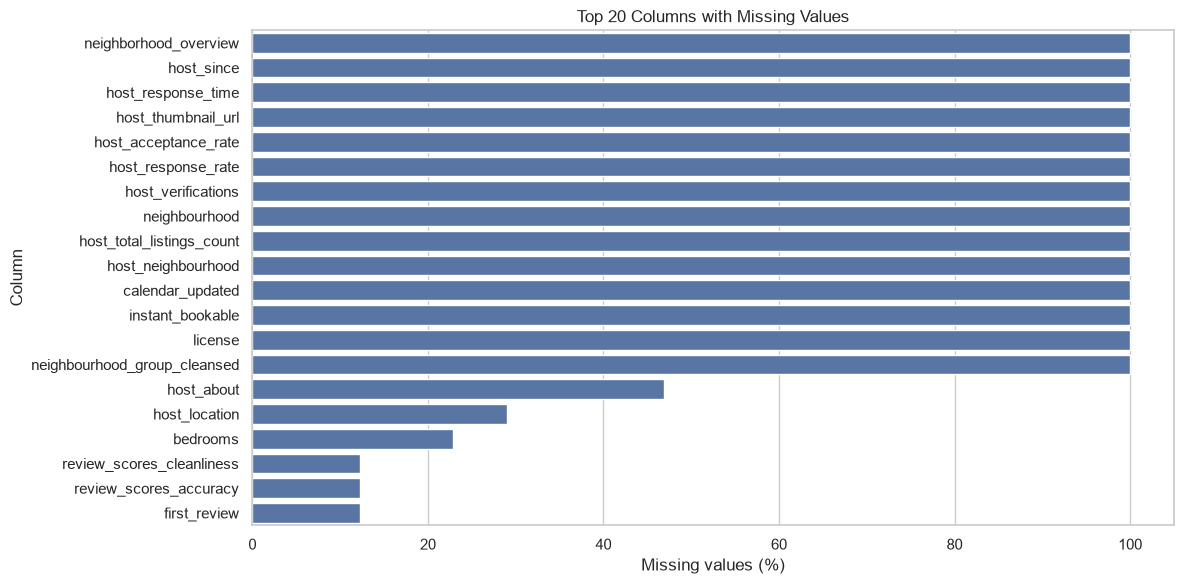

In [8]:
# Visualize the missing values
missing_plot = missing[missing["Missing_Count"] > 0].head(20)

if not missing_plot.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing_plot["Missing_Percentage"],
        y=missing_plot.index
    )
    plt.title("Top 20 Columns with Missing Values")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()

In [10]:
# Handle missing values selectively

# Remove duplicate records
df = df.drop_duplicates().copy()

# Fill missing numerical values using the median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with an explicit label
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna("Unknown")

print("Remaining missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Remaining missing values: 6860
Duplicate rows: 0


In [ ]:
# Clean price and numeric columns

# Convert price into numeric format
if "price" in df.columns:
    df["price"] = pd.to_numeric(
        df["price"]
          .astype("string")
          .str.replace(r"[$,]", "", regex=True)
          .str.strip(),
        errors="coerce"
    )

# Convert important numeric fields when available
numeric_features = [
    "minimum_nights",
    "maximum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365",
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "review_scores_rating"
]

for col in numeric_features:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert date columns if available
for col in ["last_review", "first_review"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

display(df.head())
print(df.dtypes)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20260616211424,2026-06-16,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://a0.muscache.com/pictures/44627226/0e72...,4621559,https://www.airbnb.com/users/show/4621559,1462661762635155041,https://www.airbnb.com/users/profile/146266176...,Kenneth,NaN,13,5,13,4,"New York, NY",I am a real down to earth & cool person.,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/4621559/profi...,NaN,1,NaN,NaN,t,t,NaN,THIRD WARD,NaN,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,1.0,1 bath,2.0,2.0,"[""Kitchen"", ""Essentials"", ""Heating"", ""Wifi"", ""...",80.43,2027-03-31,2027-04-28,2252.0,80.43,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",28.0,1125.0,28.0,28.0,1125.0,1125.0,28.0,1125.0,NaN,t,0,0,0,77,2026-06-16,9,0,0,0,0,0,0.0,2014-07-01,2022-08-17,3.56,3.44,3.56,4.22,4.56,3.22,3.67,NaN,NaN,1,1,0,0,0.06
1,3820211,https://www.airbnb.com/rooms/3820211,20260616211424,2026-06-16,city scrape,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,19648678,https://www.airbnb.com/users/show/19648678,1463087024016718788,https://www.airbnb.com/users/profile/146308702...,Ming,NaN,11,10,11,10,"Albany, NY","Hello! I’m a proud resident of Albany, NY, whe...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/User/...,NaN,7,NaN,NaN,t,t,NaN,SIXTH WARD,NaN,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1.0,1 bath,1.0,1.0,"[""Free washer \u2013 In unit"", ""Microwave"", ""S...",211.0,2026-07-20,2026-07-21,211.0,211.00,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",1.0,1125.0,1.0,3.0,1125.0,1125.0,2.7,1125.0,NaN,t,0,23,53,328,2026-06-16,317,8,0,162,9,48,10128.0,2014-08-15,2026-01-25,4.75,4.88,4.87,4.85,4.81,4.82,4.78,NaN,NaN,7,7,0,0,2.20
2,5651579,https://www.airbnb.com/rooms/5651579,20260616211424,2026-06-16,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",NaN,https://a0.muscache.com/pictures/b3fc42f3-6e5e...,29288920,https://www.airbnb.com/users/show/29288920,1465431505328745177,https://www.airbnb.com/users/profile/146543150...,Gregg,NaN,11,3,11,3,"Albany, NY",I am an Albany native .I have lived in Ireland...,NaN,NaN,NaN,f,Na

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 90, dtype: object


In [ ]:
# Remove invalid prices for price analysis
if "price" in df.columns:
    valid_prices = df["price"].dropna()

    print("Missing prices:", int(df["price"].isna().sum()))
    print("Zero or negative prices:", int((df["price"] <= 0).sum()))

    df = df[
        df["price"].isna() | (df["price"] > 0)
    ].copy()

Missing prices: 32
Zero or negative prices: 0


Univariate analysis

A. Price distribution

In [16]:
import pandas as pd
import numpy as np

# Remove currency symbols and commas, then convert to numeric
df["price"] = pd.to_numeric(
    df["price"]
      .astype("string")
      .str.replace(r"[$,]", "", regex=True)
      .str.strip(),
    errors="coerce"
)

# Check the data type
print(df["price"].dtype)

# Check the first five values
print(df["price"].head())

Float64
0    80.43
1    211.0
2     97.0
3    160.0
4     86.0
Name: price, dtype: Float64


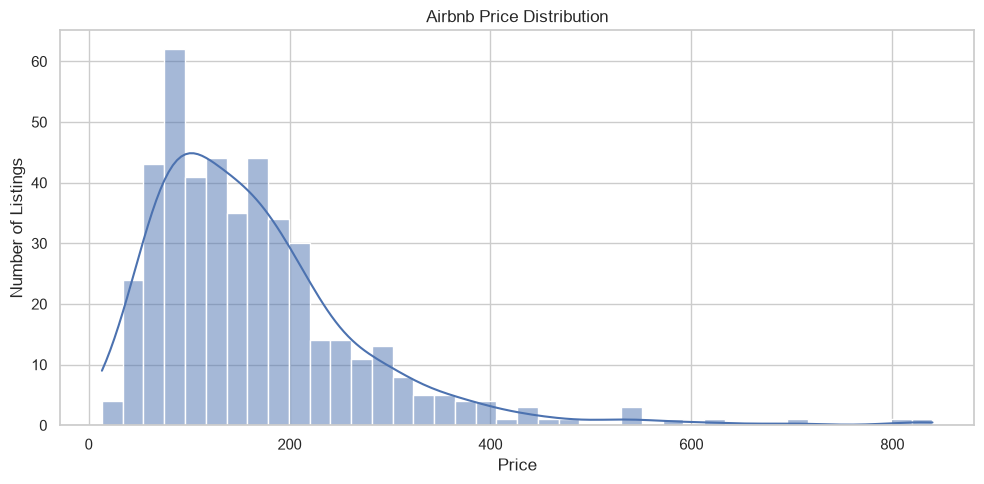

In [17]:
if "price" in df.columns:

    # Keep valid positive prices
    prices = df.loc[df["price"] > 0, "price"].dropna()

    # Calculate the 99th percentile
    if not prices.empty:
        price_limit = prices.quantile(0.99)

        # Filter prices for visualization
        prices = prices[prices <= price_limit]

        # Plot the distribution
        plt.figure(figsize=(10, 5))
        sns.histplot(prices, bins=40, kde=True)

        plt.title("Airbnb Price Distribution")
        plt.xlabel("Price")
        plt.ylabel("Number of Listings")
        plt.tight_layout()
        plt.show()
    else:
        print("No valid numeric prices found.")

B. Room-type distribution

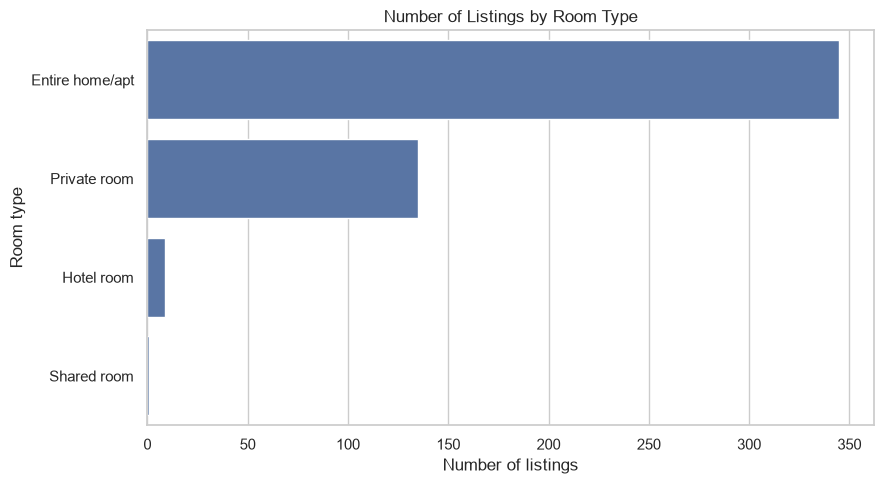

In [19]:
if "room_type" in df.columns:
    plt.figure(figsize=(9, 5))
    order = df["room_type"].value_counts().index

    sns.countplot(
        data=df,
        y="room_type",
        order=order
    )

    plt.title("Number of Listings by Room Type")
    plt.xlabel("Number of listings")
    plt.ylabel("Room type")
    plt.tight_layout()
    plt.show()

C. Availability distribution

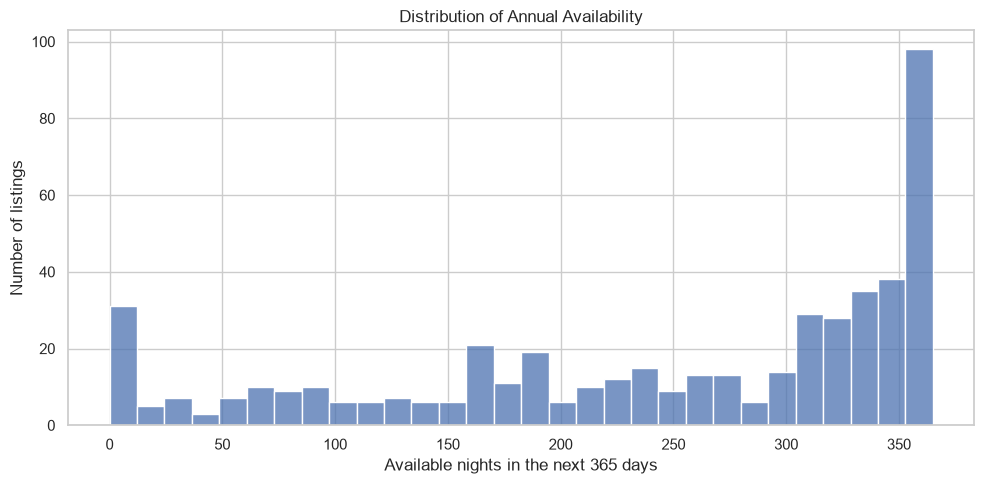

In [20]:
if "availability_365" in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=df,
        x="availability_365",
        bins=30
    )
    plt.title("Distribution of Annual Availability")
    plt.xlabel("Available nights in the next 365 days")
    plt.ylabel("Number of listings")
    plt.tight_layout()
    plt.show()

Neighborhood analysis

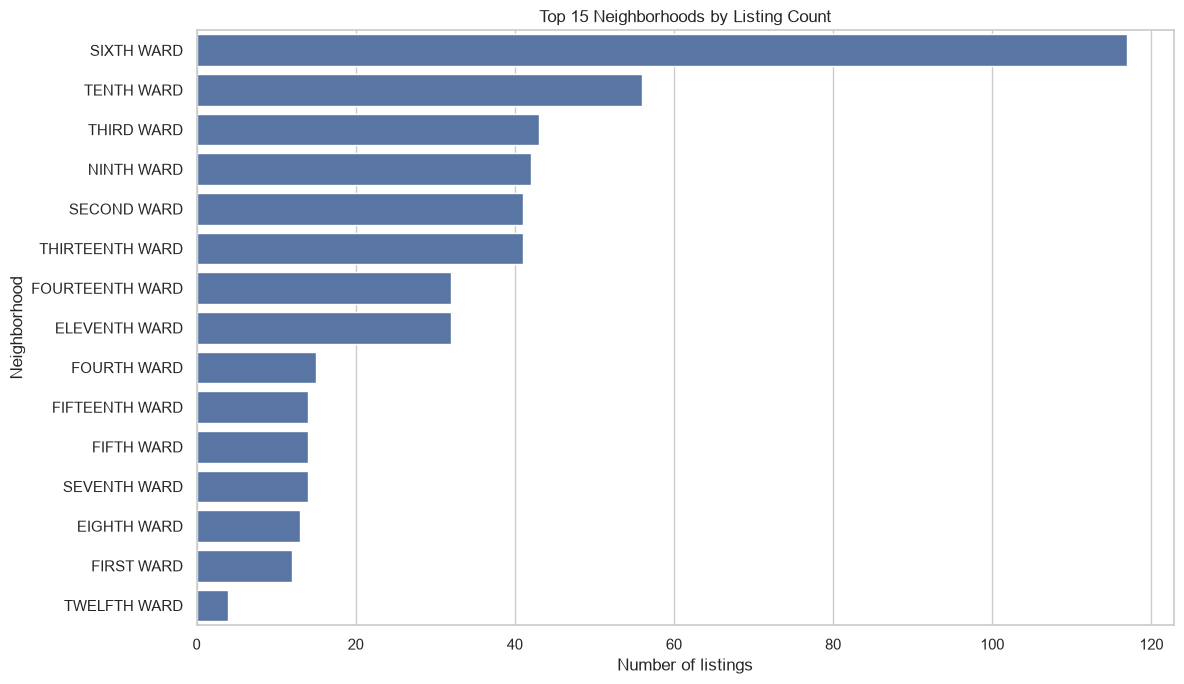

,Listing Count
neighbourhood_cleansed,
SIXTH WARD,117
TENTH WARD,56
THIRD WARD,43
NINTH WARD,42
SECOND WARD,41
THIRTEENTH WARD,41
FOURTEENTH WARD,32
ELEVENTH WARD,32
FOURTH WARD,15


In [21]:
neighborhood_col = next(
    (c for c in [
        "neighbourhood_cleansed",
        "neighbourhood",
        "neighborhood"
    ] if c in df.columns),
    None
)

if neighborhood_col:
    top_neighborhoods = (
        df[neighborhood_col]
        .fillna("Unknown")
        .value_counts()
        .head(15)
    )

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=top_neighborhoods.values,
        y=top_neighborhoods.index
    )
    plt.title("Top 15 Neighborhoods by Listing Count")
    plt.xlabel("Number of listings")
    plt.ylabel("Neighborhood")
    plt.tight_layout()
    plt.show()

    display(top_neighborhoods.rename("Listing Count").to_frame())
else:
    print("No neighborhood column found in this dataset.")

Then compare median prices by neighborhood

,count,median,mean
neighbourhood_cleansed,,,
FIFTEENTH WARD,14,295.155,346.26
EIGHTH WARD,11,257.91,252.45
SEVENTH WARD,14,205.0,233.364286
FIRST WARD,10,204.735,228.589
FOURTH WARD,14,198.835,207.383571
SECOND WARD,40,183.0,223.60275
SIXTH WARD,109,160.0,164.51156
THIRD WARD,40,124.5,161.2105
NINTH WARD,41,109.0,158.040488


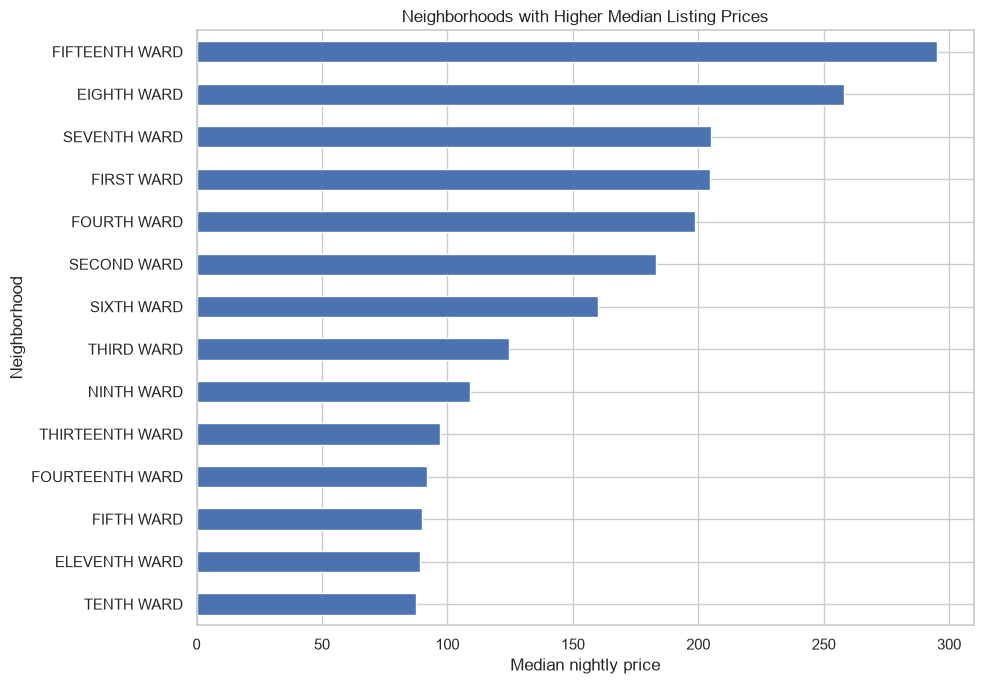

In [22]:
if neighborhood_col and "price" in df.columns:
    neighborhood_prices = (
        df.dropna(subset=["price"])
          .groupby(neighborhood_col)["price"]
          .agg(["count", "median", "mean"])
          .query("count >= 10")
          .sort_values("median", ascending=False)
          .head(15)
    )

    display(neighborhood_prices)

    neighborhood_prices["median"].sort_values().plot(
        kind="barh", figsize=(10, 7)
    )
    plt.title("Neighborhoods with Higher Median Listing Prices")
    plt.xlabel("Median nightly price")
    plt.ylabel("Neighborhood")
    plt.tight_layout()
    plt.show()

Room type and pricing analysis

In [23]:
if "room_type" in df.columns and "price" in df.columns:
    room_summary = (
        df.dropna(subset=["price"])
          .groupby("room_type")["price"]
          .agg(["count", "mean", "median", "min", "max"])
          .sort_values("median", ascending=False)
    )

    display(room_summary)

,count,mean,median,min,max
room_type,,,,,
Shared room,1,840.0,840.0,840.0,840.0
Hotel room,8,217.0,186.0,124.0,372.0
Entire home/apt,322,208.466957,166.0,72.53,1701.0
Private room,127,89.936535,71.82,13.18,331.0


Create a box plot to visualize variation in prices

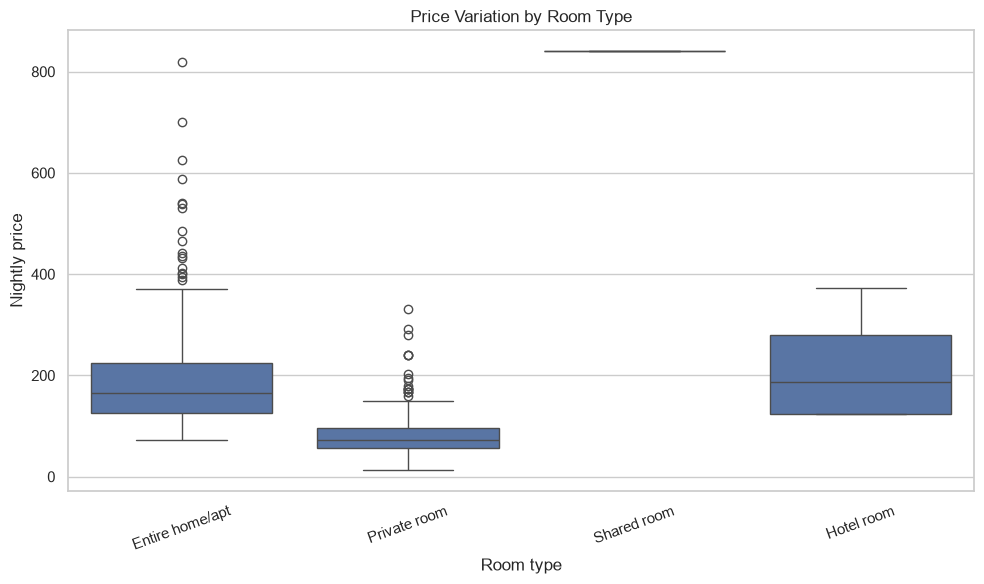

In [24]:
if "room_type" in df.columns and "price" in df.columns:
    price_cap = df["price"].quantile(0.99)

    plot_df = df[
        df["price"].between(0.01, price_cap)
    ].copy()

    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=plot_df,
        x="room_type",
        y="price"
    )
    plt.title("Price Variation by Room Type")
    plt.xlabel("Room type")
    plt.ylabel("Nightly price")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

Review and rating analysis

Check which review-related fields exist

In [25]:
review_columns = [
    col for col in df.columns
    if "review" in col.lower() or "rating" in col.lower()
]

print("Review-related columns:", review_columns)

Review-related columns: ['number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'reviews_per_month']


Analyze the number of reviews

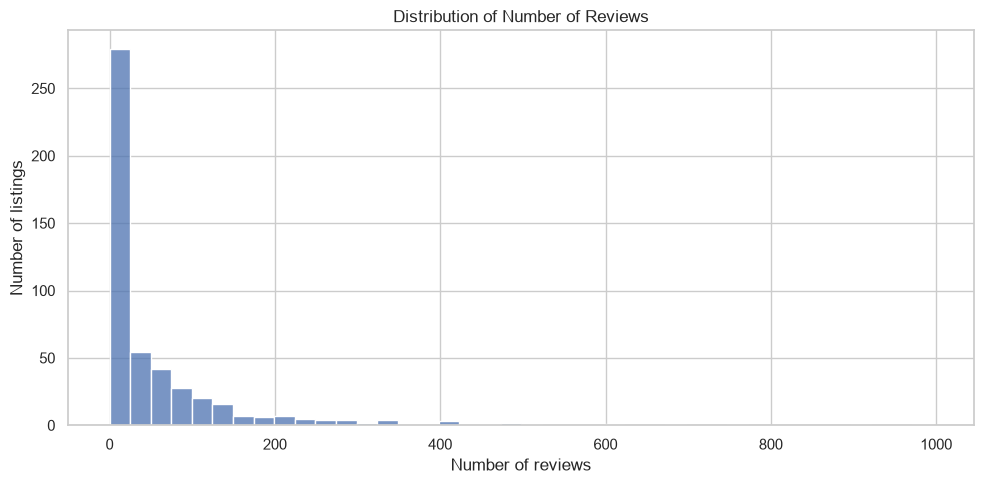

In [26]:
if "number_of_reviews" in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=df,
        x="number_of_reviews",
        bins=40
    )
    plt.title("Distribution of Number of Reviews")
    plt.xlabel("Number of reviews")
    plt.ylabel("Number of listings")
    plt.tight_layout()
    plt.show()

Analyze ratings by room type, if a rating column is available

In [27]:
if "review_scores_rating" in df.columns:
    rating_data = df.dropna(subset=["review_scores_rating"])

    if "room_type" in df.columns:
        rating_summary = (
            rating_data.groupby("room_type")["review_scores_rating"]
            .agg(["count", "mean", "median"])
        )
        display(rating_summary)

,count,mean,median
room_type,,,
Entire home/apt,319,4.688715,4.84
Hotel room,1,1.000000,1.00
Private room,109,4.795596,4.92
Shared room,1,4.670000,4.67


Correlation analysis

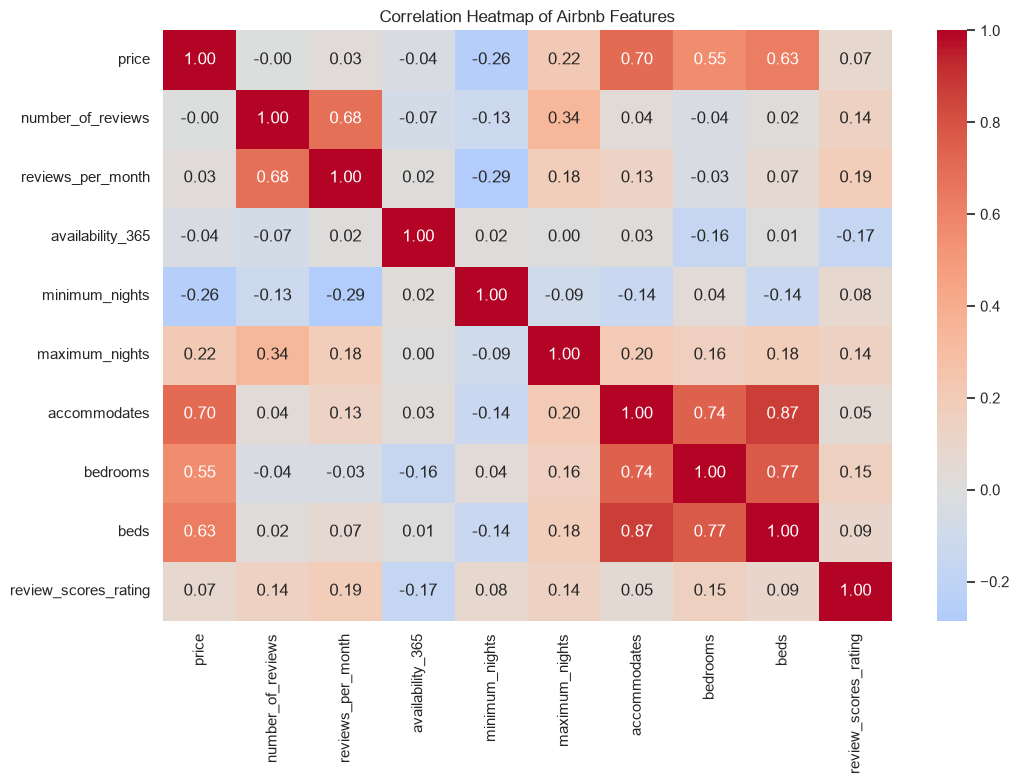

In [28]:
correlation_features = [
    "price",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365",
    "minimum_nights",
    "maximum_nights",
    "accommodates",
    "bedrooms",
    "beds",
    "review_scores_rating"
]

available_features = [
    c for c in correlation_features
    if c in df.columns
    and pd.api.types.is_numeric_dtype(df[c])
]

if len(available_features) >= 2:
    corr = df[available_features].corr()

    plt.figure(figsize=(11, 8))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0
    )
    plt.title("Correlation Heatmap of Airbnb Features")
    plt.tight_layout()
    plt.show()

Scatter plot: Price versus reviews

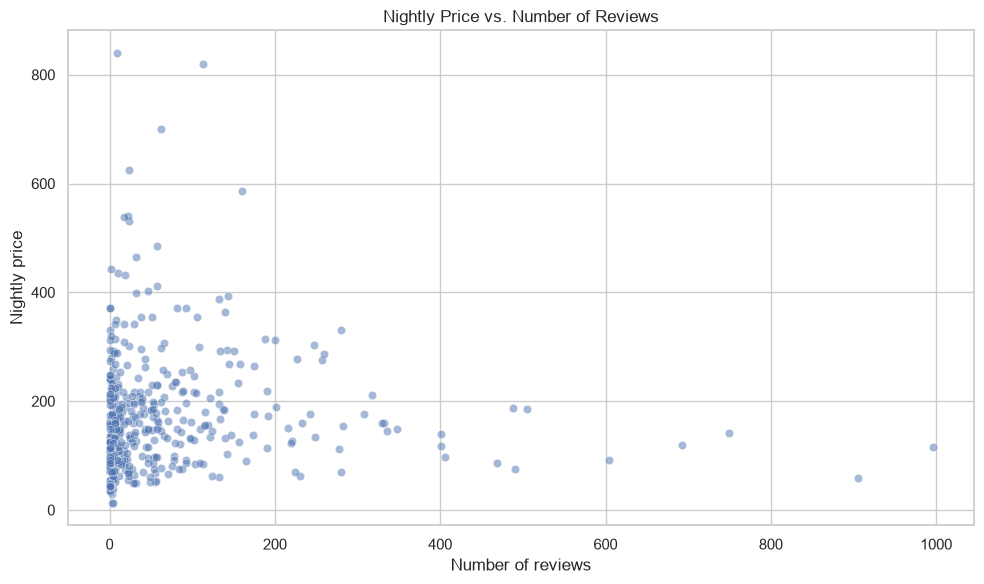

In [29]:
if "price" in df.columns and "number_of_reviews" in df.columns:
    scatter_df = df.dropna(
        subset=["price", "number_of_reviews"]
    )

    scatter_df = scatter_df[
        scatter_df["price"].between(
            0.01, scatter_df["price"].quantile(0.99)
        )
    ]

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=scatter_df,
        x="number_of_reviews",
        y="price",
        alpha=0.5
    )
    plt.title("Nightly Price vs. Number of Reviews")
    plt.xlabel("Number of reviews")
    plt.ylabel("Nightly price")
    plt.tight_layout()
    plt.show()

Sentiment analysis

In [30]:
# Load the reviews data
reviews_path = DATA_DIR / "reviews.csv"

reviews_df = pd.read_csv(reviews_path, low_memory=False)

display(reviews_df.head())
print(reviews_df.columns.tolist())

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,2992450,15066586,2014-07-01,16827297,Kristen,Large apartment; nice kitchen and bathroom. Ke...
1,2992450,21810844,2014-10-24,22648856,Christopher,"This may be a little late, but just to say Ken..."
2,2992450,27434334,2015-03-04,45406,Altay,The apartment was very clean and convenient to...
3,2992450,28524578,2015-03-25,5485362,John,Kenneth was ready when I got there and arrange...
4,2992450,35913434,2015-06-23,15772025,Jennifer,We were pleased to see how 2nd Street and the ...


['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']


,comments,sentiment_score,sentiment
0,Large apartment; nice kitchen and bathroom. Ke...,0.7545,Positive
1,"This may be a little late, but just to say Ken...",0.9331,Positive
2,The apartment was very clean and convenient to...,0.8883,Positive
3,Kenneth was ready when I got there and arrange...,0.9907,Positive
4,We were pleased to see how 2nd Street and the ...,0.9883,Positive


sentiment
Positive    27413
Neutral      1053
Negative      572
Name: count, dtype: int64


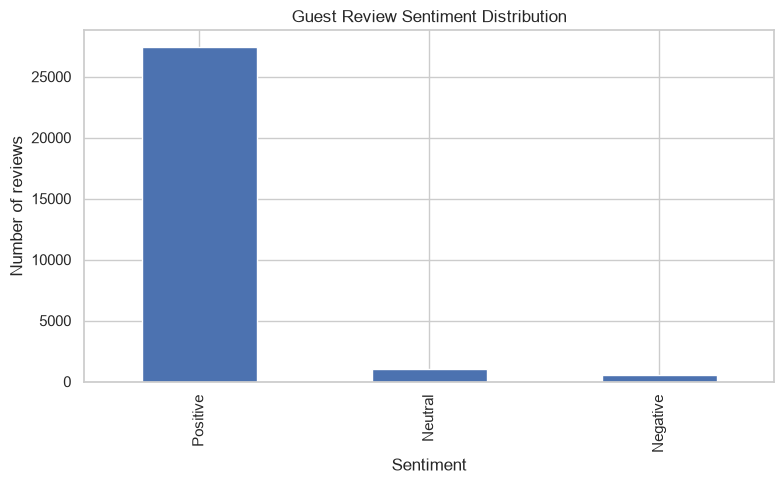

In [31]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

if "comments" in reviews_df.columns:
    sentiment_analyzer = SentimentIntensityAnalyzer()

    reviews_df = reviews_df.dropna(subset=["comments"]).copy()

    reviews_df["sentiment_score"] = reviews_df["comments"].apply(
        lambda text: sentiment_analyzer
        .polarity_scores(str(text))["compound"]
    )

    reviews_df["sentiment"] = np.select(
        [
            reviews_df["sentiment_score"] >= 0.05,
            reviews_df["sentiment_score"] <= -0.05
        ],
        [
            "Positive",
            "Negative"
        ],
        default="Neutral"
    )

    display(reviews_df[["comments", "sentiment_score", "sentiment"]].head())

    print(reviews_df["sentiment"].value_counts())

    reviews_df["sentiment"].value_counts().plot(
        kind="bar", figsize=(8, 5)
    )
    plt.title("Guest Review Sentiment Distribution")
    plt.xlabel("Sentiment")
    plt.ylabel("Number of reviews")
    plt.tight_layout()
    plt.show()

Create final summary tables

In [32]:
print("Total listings:", len(df))

if "price" in df.columns:
    print("Average nightly price:", round(df["price"].mean(), 2))
    print("Median nightly price:", round(df["price"].median(), 2))

if "room_type" in df.columns:
    print("\nListings by room type:")
    display(df["room_type"].value_counts().to_frame("Listing Count"))

if neighborhood_col:
    print("\nTop 10 neighborhoods by listing count:")
    display(
        df[neighborhood_col]
        .value_counts()
        .head(10)
        .to_frame("Listing Count")
    )

if "availability_365" in df.columns:
    print(
        "\nAverage available nights:",
        round(df["availability_365"].mean(), 2)
    )

if "review_scores_rating" in df.columns:
    print(
        "\nAverage available rating:",
        round(df["review_scores_rating"].mean(), 2)
    )

Total listings: 490
Average nightly price: 177.13
Median nightly price: 145.67

Listings by room type:


,Listing Count
room_type,
Entire home/apt,345
Private room,135
Hotel room,9
Shared room,1



Top 10 neighborhoods by listing count:


,Listing Count
neighbourhood_cleansed,
SIXTH WARD,117
TENTH WARD,56
THIRD WARD,43
NINTH WARD,42
SECOND WARD,41
THIRTEENTH WARD,41
FOURTEENTH WARD,32
ELEVENTH WARD,32
FOURTH WARD,15



Average available nights: 242.89

Average available rating: 4.71


Export the cleaned dataset

In [33]:
output_path = DATA_DIR / "listings_cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)
print("Final dataset shape:", df.shape)

Cleaned dataset saved to: d:\Adarsh\Hexa Solutions\Data Analytics Level 3\Projects\Assignment Projects\6 - AIRBNB Dashboarding\Airbnb_Data_Analysis\data\listings_cleaned.csv
Final dataset shape: (490, 90)
